# 예측 단계별 정보의 가치 (10,473편)

지도교수 질문 "날씨·바람만으로 예측이 되는가"에 답하고, 2026-11-14 방향 전환 뒤 더한 정보가
각각 얼마나 기여하는지 잰다. 모든 수치는 **주간 4폴드 평균**이다. 마지막 4주(10-17~11-13)를 한 주씩
테스트하고, 각 주는 그 이전 자료 전부로 학습한다. `train.py --weekly` 와 같은 방식이다.

> ⚠️ **개발 구간(~11-13) 수치다.** 이 구간을 보면서 피처를 골랐으므로 낙관적일 수 있다. 보고서의 최종
> 수치는 11-14~11-30 수집분으로 한 번 잰다. 이 노트북은 그 뒤 데이터 마일스톤에서 다시 실행한다.

**해석은 각 절의 출력을 실행한 뒤에 적었다.**

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import DATA_PROCESSED
from train import (
    DELAY_THRESHOLD,
    FEATURES_PRE,
    FEATURES_ROT,
    FLIGHT_HIST,
    ORIGIN_WX,
    TARGET,
    WARN_PROB,
    fit_warning,
    fit_xgb,
)

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# 대시보드와 같은 검증된 팔레트 (dataviz 지침)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a87"

# 11-14 이후 수집분은 최종 검증용으로 남긴다 (src/CLAUDE.md). 이 노트북은 그 앞까지만 본다.
DEV_END = pd.Timestamp("2026-11-14")
d = pd.read_parquet(DATA_PROCESSED / "dataset.parquet")
d = d[d["sched_time"] < DEV_END].sort_values("sched_time").reset_index(drop=True)

# 주간 4폴드: 마지막 4주를 한 주씩 테스트, 각 주는 그 이전 전부로 학습 (train.py --weekly 와 같다)
STARTS = [DEV_END - pd.Timedelta(weeks=k) for k in (4, 3, 2, 1)]
print(f"{len(d):,}편 ({d.sched_time.min():%m-%d} ~ {d.sched_time.max():%m-%d}) · 폴드 시작 {[f'{s:%m-%d}' for s in STARTS]}")

10,473편 (09-07 ~ 11-13) · 폴드 시작 ['10-17', '10-24', '10-31', '11-07']


In [2]:
def folds(df):
    for a in STARTS:
        yield df[df.sched_time < a], df[(df.sched_time >= a) & (df.sched_time < a + pd.Timedelta(weeks=1))]


def weekly_preds(df, feats):
    """폴드별 예측을 이어 붙인다. feats=None 이면 학습셋 중앙값(베이스라인)."""
    out = []
    for tr, te in folds(df):
        if feats is None:
            p = np.full(len(te), tr[TARGET].median())
        else:
            model, cats = fit_xgb(feats, tr)
            p = model.predict(te[feats].astype(cats))
        out.append(te.assign(pred=p))
    return pd.concat(out)


def summarize(p):
    e = (p[TARGET] - p["pred"]).abs()
    return pd.Series({"MAE": e.mean(), "±10분 이내": (e <= 10).mean(), "n": len(p)})

## 1. 정보를 하나씩 더하면 오차가 얼마나 주나

**김해 기상만으로는 예측이 되지 않는다.** 김해 기상만 쓴 모델은 MAE 15.57분으로 베이스라인(15.62분)과
같고, ±10분 이내 비율은 오히려 49% 로 베이스라인(53%)보다 낮다. 노선·시간대에 김해 기상을 더해도 0.01분뿐이다.

기여가 큰 정보는 **노선·시간대(−2.1분), 편명 이력(−0.89분), 회전편 지연(−0.62분)** 순이다. 편명 이력에는 최근 7회 이력(`fn_med7`·`fn_late7`)이, 회전편 지연에는 짝편 매칭 보강
(왕복 불가 간격 제외·같은 항공사·출발지행 대체)이 반영된 수치다.
출발지 기상은 −0.07분으로 작다. 단일 분할(테스트 10-31~)에서는 −0.33분이었으나 네 주 평균으로는
대부분 사라진다. 출발지 악기상 날이 적어서일 수 있고, 지금 표본으로는 효과가 작다고만 말할 수 있다.

In [3]:
ROUTE = ["origin", "line", "airline", "hour", "dow", "month"]
KIMHAE_WX = [f for f in FEATURES_PRE if f not in ROUTE + ORIGIN_WX + FLIGHT_HIST]

steps = {
    "베이스라인 (중앙값)": None,
    "김해 기상만": KIMHAE_WX,
    "노선·시간대": ROUTE,
    "+ 김해 기상": ROUTE + KIMHAE_WX,
    "+ 출발지 기상": ROUTE + KIMHAE_WX + ORIGIN_WX,
    "+ 편명 이력 (= 사전예측)": FEATURES_PRE,
    "+ 회전편 지연 (= 회전편후)": FEATURES_ROT,
}
abl = pd.DataFrame({k: summarize(weekly_preds(d, f)) for k, f in steps.items()}).T
abl["n"] = abl["n"].astype(int)
abl

,MAE,±10분 이내,n
베이스라인 (중앙값),15.62,0.53,4274
김해 기상만,15.57,0.49,4274
노선·시간대,13.49,0.56,4274
+ 김해 기상,13.48,0.55,4274
+ 출발지 기상,13.41,0.55,4274
+ 편명 이력 (= 사전예측),12.52,0.59,4274
+ 회전편 지연 (= 회전편후),11.90,0.61,4274


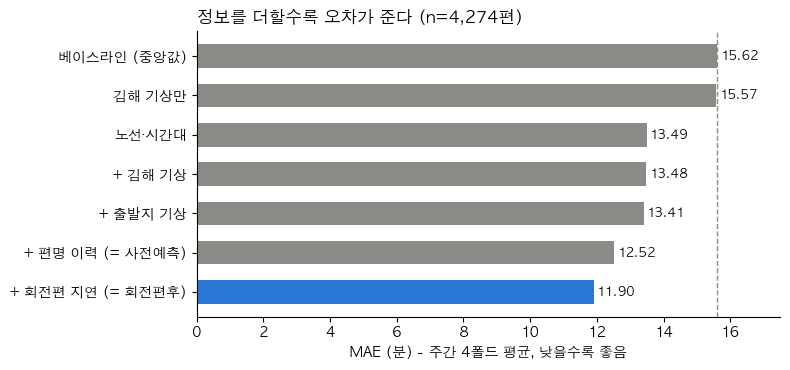

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = abl.index[::-1]
colors = [BLUE if n.startswith("+ 회전편") else GREY for n in names]
ax.barh(names, abl.loc[names, "MAE"], color=colors, height=0.6)
for i, v in enumerate(abl.loc[names, "MAE"]):
    ax.text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(abl.loc["베이스라인 (중앙값)", "MAE"], color=GREY, ls="--", lw=1)
ax.set_xlabel("MAE (분) - 주간 4폴드 평균, 낮을수록 좋음")
ax.set_title(f"정보를 더할수록 오차가 준다 (n={int(abl.n.iloc[0]):,}편)", loc="left")
ax.set_xlim(0, abl.MAE.max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 2. 국내선: 단계별 정보의 가치

국내선 1,349편(4주 합계)에서 **출발지연을 알면 MAE 가 11.68 → 3.68분으로 8.0분 준다.** 그 앞의
두 단계(사전 −0.94분, 회전편 −0.77분)를 합친 것의 4배가 넘는다. 시간표에 약 25분 여유가 있어
출발지연을 알면 남는 불확실성이 비행시간 편차뿐이기 때문이다(README '이륙 후 모델의 하한선').

주의: 국내선에서는 사전예측·회전편후의 **±10분 이내 비율(58%·60%)이 베이스라인(61%)보다 낮다.**
국내선은 조기도착이 촘촘히 몰려 있어 중앙값 찍기가 이미 잘 맞는다. MAE 로는 앞서도 평범한 편에서는
아직 이기지 못한다. 전체 표본(1절)에서는 61% 대 53% 로 앞선다.

In [5]:
dom = d[d["dep_delay"].notna()]
stage = {
    "베이스라인": None,
    "사전예측": FEATURES_PRE,
    "회전편후": FEATURES_ROT,
    "이륙후": [*FEATURES_ROT, "dep_delay"],
}
dom_tab = pd.DataFrame({k: summarize(weekly_preds(dom, f)) for k, f in stage.items()}).T
dom_tab["n"] = dom_tab["n"].astype(int)
dom_tab["앞 단계 대비 (분)"] = dom_tab["MAE"].diff()
dom_tab

,MAE,±10분 이내,n,앞 단계 대비 (분)
베이스라인,13.39,0.61,1349,NaN
사전예측,12.45,0.58,1349,-0.94
회전편후,11.68,0.60,1349,-0.77
이륙후,3.68,0.95,1349,-8.00


## 3. 지연경고: 기준 확률을 바꾸면

4주 동안 15분 이상 지연은 667편(16%)이었다. **채택한 기준 0.3에서 지연의 52% 를 잡고, 경고의 53% 는
헛경보다.** 경고는 4주에 747번, 하루 약 27번이다.

기준은 쓰임새로 정한다. 마중·환승처럼 놓치는 비용이 크면 0.2(적중 63%·오경보 62%)가 낫다.
헛경보가 신뢰를 깎는 승객 알림이라면 0.5(적중 32%·오경보 41%)가 낫다. 어느 기준에서도 오경보율이
28% 아래로 내려가지 않는다. 출발 전 정보만으로는 지연을 확신할 수 있는 편이 드물다는 뜻이다.

In [6]:
probs = []
for tr, te in folds(d):
    clf, cats = fit_warning(FEATURES_ROT, tr)
    probs.append(te.assign(prob=clf.predict_proba(te[FEATURES_ROT].astype(cats))[:, 1]))
probs = pd.concat(probs)
actual = probs[TARGET] >= DELAY_THRESHOLD

rows = []
for th in np.arange(0.1, 0.71, 0.05):
    flag = probs["prob"] >= th
    hit = (actual & flag).sum()
    rows.append({"기준": round(th, 2), "적중률": hit / actual.sum(), "오경보율": 1 - hit / max(flag.sum(), 1), "경고 수": int(flag.sum())})
curve = pd.DataFrame(rows)
print(f"15분 이상 지연 {int(actual.sum())}편 / {len(probs):,}편 (4주 합계)")
curve

15분 이상 지연 667편 / 4,274편 (4주 합계)


,기준,적중률,오경보율,경고 수
0,0.10,0.80,0.70,1775
1,0.15,0.72,0.65,1395
2,0.20,0.63,0.62,1123
3,0.25,0.55,0.58,887
4,0.30,0.52,0.53,747
5,0.35,0.45,0.49,598
6,0.40,0.41,0.46,508
7,0.45,0.36,0.44,427
8,0.50,0.32,0.41,364
9,0.55,0.28,0.38,300


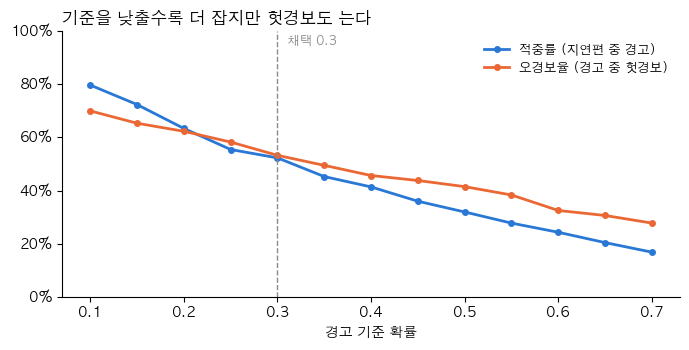

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve["기준"], curve["적중률"], color=BLUE, lw=2, marker="o", ms=4, label="적중률 (지연편 중 경고)")
ax.plot(curve["기준"], curve["오경보율"], color=ORANGE, lw=2, marker="o", ms=4, label="오경보율 (경고 중 헛경보)")
ax.axvline(WARN_PROB, color=GREY, ls="--", lw=1)
ax.text(WARN_PROB + 0.01, 0.95, f"채택 {WARN_PROB}", fontsize=9, color=GREY)
ax.set_xlabel("경고 기준 확률")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("기준을 낮출수록 더 잡지만 헛경보도 는다", loc="left")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4. 모델은 무엇을 보나 — 피처 중요도

**편명 이력(`fn_med` 18%, `fn_med7` 16%, `fn_late7` 4%)이 모델이 가장 많이 기대는 정보다.** 같은 편명은 시간표·기종·
여유시간이 거의 같아, 그 편의 평소 지연이 가장 좋은 출발점이 된다.

김해 박무(`wx_br`)가 3% 로 6위에 있지만, 1절에서 김해 기상을 더해도 성능은 0.01분만 달라졌다. gain 은 '자주 갈라
쓴 정도'이지 '정확도 기여'가 아니다. 기여를 말할 때는 1절의 제거 실험을 인용한다.

fn_med          0.18
fn_med7         0.16
rot_delay       0.05
fn_late7        0.04
origin          0.04
wx_br           0.03
o_ra            0.03
fn_late         0.03
o_ts            0.03
fn_n            0.03
o_vis           0.03
visibility_km   0.02
dtype: float64

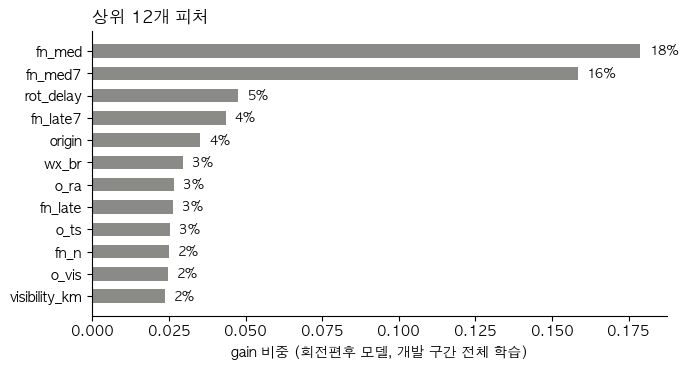

In [8]:
model, cats = fit_xgb(FEATURES_ROT, d)
gain = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
share = (gain / gain.sum()).head(12)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(share.index[::-1], share.values[::-1], color=GREY, height=0.6)
for i, v in enumerate(share.values[::-1]):
    ax.text(v + 0.003, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlabel("gain 비중 (회전편후 모델, 개발 구간 전체 학습)")
ax.set_title("상위 12개 피처", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
share.round(3)

## 5. 어디서 틀리나 — 실제 지연 구간별 오차

**모델은 큰 지연을 덜 틀리게 됐지만 여전히 크게 틀린다.** 15~60분 지연 576편에서 MAE 가
35.9 → 21.7분으로 줄었다. 그러나 60분 이상 지연 91편(2%)은 평균 +17분으로만 예측해 97분이나 빗나간다.
이런 편은 출발 전 정보로는 거의 보이지 않는다.

0~15분 조기도착 1,750편에서만 베이스라인(3.6분)이 모델(6.8분)보다 낫다. 베이스라인의 고정값 −7분이
마침 이 구간 한가운데에 있어서다. 나머지 네 구간에서는 모두 모델이 낫다.

In [9]:
base = weekly_preds(d, None)
rot = weekly_preds(d, FEATURES_ROT)
bins = [-np.inf, -15, 0, 15, 60, np.inf]
labels = ["15분 이상 조기", "0~15분 조기", "0~15분 지연", "15~60분 지연", "60분 이상 지연"]
rot["구간"] = pd.cut(rot[TARGET], bins, labels=labels, right=False)
base["구간"] = pd.cut(base[TARGET], bins, labels=labels, right=False)
by = pd.DataFrame({
    "n": rot.groupby("구간", observed=True).size(),
    "베이스라인 MAE": base.assign(e=(base[TARGET] - base.pred).abs()).groupby("구간", observed=True).e.mean(),
    "회전편후 MAE": rot.assign(e=(rot[TARGET] - rot.pred).abs()).groupby("구간", observed=True).e.mean(),
    "회전편후 평균 예측": rot.groupby("구간", observed=True).pred.mean(),
})
by

,n,베이스라인 MAE,회전편후 MAE,회전편후 평균 예측
구간,,,,
15분 이상 조기,975,17.45,10.54,-16.20
0~15분 조기,1750,3.63,6.79,-4.68
0~15분 지연,882,13.27,8.41,0.80
15~60분 지연,576,35.92,21.68,8.06
60분 이상 지연,91,120.74,96.57,16.65
